# Practice 11 — Object Detection and Segmentation

**Goal:** read what a pretrained detector and a segmentation model return — *where*, not only *what*.

| Task | Output per object | Numbers per object |
|:---|:---|:---|
| Classification | one label for the whole image | 1 class index |
| Object detection | one axis-aligned box | 4 coordinates + class + confidence |
| Instance segmentation | one per-pixel mask | a 0/1 grid + class + confidence |

- Nothing is trained here → the weights arrive pretrained on the 80 COCO classes

---
## Step 0. Setup

- `ultralytics` → the YOLO models and their inference API
- A path given to `YOLO(...)` → the weights are downloaded there, not into the working directory

In [1]:
import subprocess
import sys

try:
    import ultralytics
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'], check=True)
    import ultralytics

print(f'ultralytics {ultralytics.__version__}')

ultralytics 8.4.120


In [2]:
import urllib.request
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO

np.random.seed(42)
torch.manual_seed(42)

# every file this notebook writes goes under one of these two folders
BUILD = Path('build')
DATA = Path('data')
BUILD.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)

print(f'GPU available : {torch.cuda.is_available()}')

GPU available : True


image shape : (1380, 2070, 3)   height, width, channels


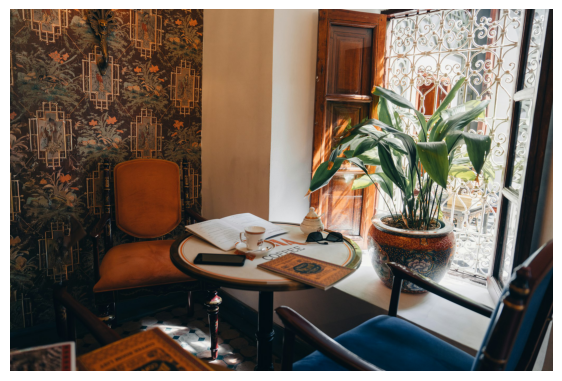

In [3]:
image_path = DATA / 'detection_sample.jpg'
if not image_path.exists():
    urllib.request.urlretrieve(
        'https://images.unsplash.com/photo-1760681557777-bfac1f18cf90'
        '?ixlib=rb-4.1.0&auto=format&fit=crop&q=80&w=2070', image_path)

second_image_path = DATA / 'bus.jpg'
if not second_image_path.exists():
    urllib.request.urlretrieve('https://ultralytics.com/images/bus.jpg', second_image_path)

image = np.array(Image.open(image_path).convert('RGB'))
print(f'image shape : {image.shape}   height, width, channels')

plt.figure(figsize=(7, 5))
plt.imshow(image)
plt.axis('off')
plt.show()

---
## Step 1. Running the Detector

- `yolo11n` → the smallest YOLO11, already knows the 80 COCO classes
- `conf=0.25` → drops detections below 25% confidence
- `predict` returns a list → one `Results` object per input image

In [4]:
detection_model = YOLO(str(BUILD / 'yolo11n.pt'))
detection_results = detection_model.predict(source=str(image_path), conf=0.25, verbose=False)

print(f'results returned : {len(detection_results)}   one per input image')

detection_result = detection_results[0]
print(f'objects found    : {len(detection_result.boxes)}')
print(f'orig_shape       : {detection_result.orig_shape}')

results returned : 1   one per input image
objects found    : 6
orig_shape       : (1380, 2070)


---
## Step 2. What Is Inside `result.boxes`

- One row per detected object in every attribute

| Attribute | Shape | Meaning |
|:---|:---|:---|
| `boxes.xyxy` | (N, 4) | corners in pixels, $(x_1, y_1, x_2, y_2)$ |
| `boxes.xywhn` | (N, 4) | centre and size, divided by image size |
| `boxes.conf` | (N,) | confidence |
| `boxes.cls` | (N,) | class index, stored as a float → `int()` before `result.names[...]` |

In [5]:
print(f'boxes.xyxy  : {tuple(detection_result.boxes.xyxy.shape)}')
print(f'boxes.xywhn : {tuple(detection_result.boxes.xywhn.shape)}')
print(f'boxes.conf  : {tuple(detection_result.boxes.conf.shape)}')
print(f'boxes.cls   : {tuple(detection_result.boxes.cls.shape)}')
print(f'names       : {len(detection_result.names)} class names')
print()

for index in range(len(detection_result.boxes)):
    class_index = int(detection_result.boxes.cls[index])
    confidence = float(detection_result.boxes.conf[index])
    x1, y1, x2, y2 = detection_result.boxes.xyxy[index].cpu().numpy()
    print(f'{detection_result.names[class_index]:<14s} conf={confidence:.3f}  '
          f'x1={x1:7.1f} y1={y1:7.1f} x2={x2:7.1f} y2={y2:7.1f}')

boxes.xyxy  : (6, 4)
boxes.xywhn : (6, 4)
boxes.conf  : (6,)
boxes.cls   : (6,)
names       : 80 class names

chair          conf=0.833  x1= 1016.6 y1=  872.0 x2= 2069.0 y2= 1366.0
potted plant   conf=0.800  x1= 1187.1 y1=  248.7 x2= 1851.2 y2= 1067.6
cup            conf=0.761  x1=  886.8 y1=  824.7 x2=  975.6 y2=  918.5
chair          conf=0.711  x1=  317.1 y1=  567.4 x2=  715.7 y2= 1172.7
dining table   conf=0.563  x1=  630.4 y1=  771.2 x2= 1358.1 y2= 1363.9
chair          conf=0.412  x1=  161.9 y1= 1039.6 x2=  749.1 y2= 1368.1


$$x_1 = (c_x - w/2)\,W, \quad y_1 = (c_y - h/2)\,H, \quad
x_2 = (c_x + w/2)\,W, \quad y_2 = (c_y + h/2)\,H$$

- $(c_x, c_y, w, h)$ = one `xywhn` row; $W$, $H$ = image width and height → the result is the `xyxy` row
- Normalized coordinates survive a resize of the image, pixel coordinates do not

In [6]:
image_height, image_width = detection_result.orig_shape

center_x, center_y, box_width, box_height = detection_result.boxes.xywhn[0].cpu().numpy()
x1_from_normalized = (center_x - box_width / 2) * image_width
y1_from_normalized = (center_y - box_height / 2) * image_height
x2_from_normalized = (center_x + box_width / 2) * image_width
y2_from_normalized = (center_y + box_height / 2) * image_height

print('first box, two ways of writing the same rectangle')
print(f'xyxy               : {detection_result.boxes.xyxy[0].cpu().numpy()}')
print(f'xywhn -> pixels    : [{x1_from_normalized:.4f} {y1_from_normalized:.4f} '
      f'{x2_from_normalized:.4f} {y2_from_normalized:.4f}]')

first box, two ways of writing the same rectangle
xyxy               : [     1016.6      872.03        2069        1366]
xywhn -> pixels    : [1016.6494 872.0330 2068.9573 1366.0405]


---
## Step 3. Drawing the Boxes

- `result.plot()` → annotated image in **BGR** order, so the channels are reversed for matplotlib

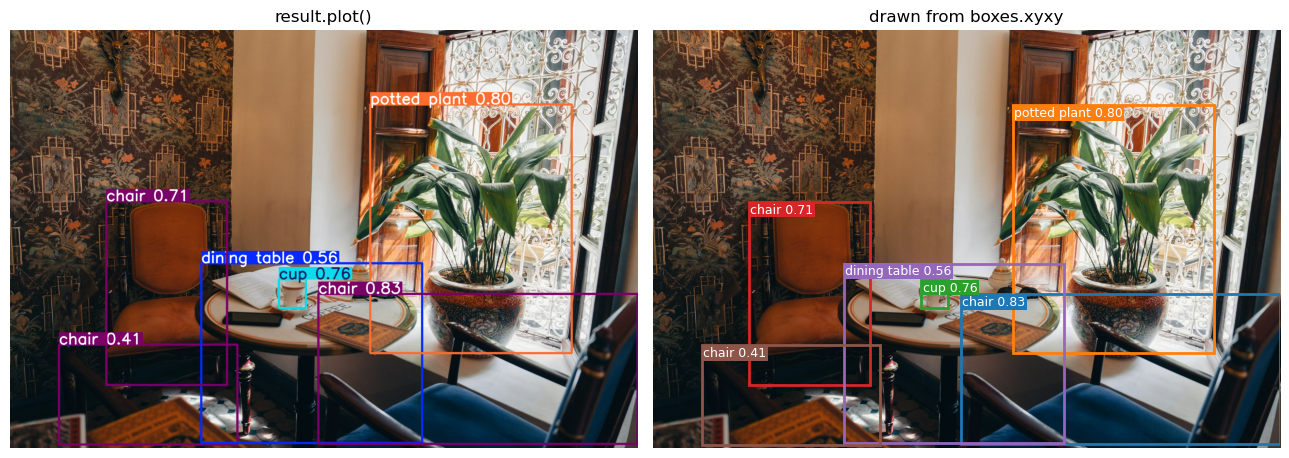

In [7]:
annotated_image = detection_result.plot()[:, :, ::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(annotated_image)
axes[0].set_title('result.plot()')
axes[0].axis('off')

axes[1].imshow(image)
for index in range(len(detection_result.boxes)):
    class_index = int(detection_result.boxes.cls[index])
    confidence = float(detection_result.boxes.conf[index])
    x1, y1, x2, y2 = detection_result.boxes.xyxy[index].cpu().numpy()
    instance_color = plt.cm.tab10(index % 10)
    axes[1].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                                fill=False, edgecolor=instance_color, linewidth=2))
    # the label sits inside the top edge, so a box touching y=0 keeps its text on the image
    axes[1].text(x1 + 4, y1 + 4, f'{detection_result.names[class_index]} {confidence:.2f}',
                 color='white', fontsize=9, va='top', ha='left', clip_on=True,
                 bbox=dict(facecolor=instance_color, edgecolor='none', pad=1))
axes[1].set_title('drawn from boxes.xyxy')
axes[1].axis('off')

plt.tight_layout(); plt.show()

- Same rectangles in both panels → `plot()` is convenient, the hand-written loop shows what the coordinates mean

---
## Step 4. The Confidence Threshold

- Only `conf` changes between the two calls → the threshold decides which detections survive

In [8]:
low_threshold_result = detection_model.predict(source=str(image_path), conf=0.25, verbose=False)[0]
high_threshold_result = detection_model.predict(source=str(image_path), conf=0.50, verbose=False)[0]

low_threshold_names = []
for index in range(len(low_threshold_result.boxes)):
    low_threshold_names.append(low_threshold_result.names[int(low_threshold_result.boxes.cls[index])])

high_threshold_names = []
for index in range(len(high_threshold_result.boxes)):
    high_threshold_names.append(high_threshold_result.names[int(high_threshold_result.boxes.cls[index])])

print(f'conf=0.25 : {len(low_threshold_names):2d} objects  ' + ', '.join(low_threshold_names))
print(f'conf=0.50 : {len(high_threshold_names):2d} objects  ' + ', '.join(high_threshold_names))

conf=0.25 :  6 objects  chair, potted plant, cup, chair, dining table, chair
conf=0.50 :  5 objects  chair, potted plant, cup, chair, dining table


- Detections come sorted by confidence → the list shortens from the bottom: `chair` 0.41 drops out at `conf=0.50`

---
## Step 5. The Segmentation Model

- Everything the detector returns, plus one mask per object

| Attribute | What it holds |
|:---|:---|
| `masks.data` | a binary mask per object, as a grid of 0 and 1 |
| `masks.xy` | the outline of that mask, in original image pixels |

In [9]:
segmentation_model = YOLO(str(BUILD / 'yolo11n-seg.pt'))
segmentation_result = segmentation_model.predict(source=str(image_path), conf=0.25, verbose=False)[0]

print(f'objects found : {len(segmentation_result.boxes)}')
print(f'boxes.xyxy    : {tuple(segmentation_result.boxes.xyxy.shape)}')
print(f'masks.data    : {tuple(segmentation_result.masks.data.shape)}')
print(f'orig_shape    : {segmentation_result.orig_shape}')
print()

for index in range(len(segmentation_result.boxes)):
    class_index = int(segmentation_result.boxes.cls[index])
    confidence = float(segmentation_result.boxes.conf[index])
    outline = segmentation_result.masks.xy[index]
    print(f'{segmentation_result.names[class_index]:<14s} conf={confidence:.3f}  '
          f'masks.xy[{index}] = {outline.shape} outline points')

objects found : 7
boxes.xyxy    : (7, 4)
masks.data    : (7, 448, 640)
orig_shape    : (1380, 2070)

chair          conf=0.882  masks.xy[0] = (369, 2) outline points
cup            conf=0.846  masks.xy[1] = (31, 2) outline points
potted plant   conf=0.834  masks.xy[2] = (450, 2) outline points
chair          conf=0.728  masks.xy[3] = (218, 2) outline points
remote         conf=0.295  masks.xy[4] = (28, 2) outline points
chair          conf=0.279  masks.xy[5] = (164, 2) outline points
dining table   conf=0.266  masks.xy[6] = (503, 2) outline points


- 7 objects, one more than the detector's 6 → another weights file, slightly different detections (`remote` 0.295)
- Each `masks.data` grid is (448, 640), **not** the image size (1380, 2070) → masks come at the size `predict` resized the image to
- `retina_masks=True` → masks at the original image size

In [10]:
retina_result = segmentation_model.predict(source=str(image_path), conf=0.25,
                                           retina_masks=True, verbose=False)[0]

print(f'orig_shape             : {segmentation_result.orig_shape}')
print(f'masks.data  default    : {tuple(segmentation_result.masks.data.shape)}')
print(f'masks.data  retina     : {tuple(retina_result.masks.data.shape)}')
print(f'masks.xy[0] default    : {segmentation_result.masks.xy[0].shape}')
print(f'masks.xy[0] retina     : {retina_result.masks.xy[0].shape}')

orig_shape             : (1380, 2070)
masks.data  default    : (7, 448, 640)
masks.data  retina     : (7, 1380, 2070)
masks.xy[0] default    : (369, 2)
masks.xy[0] retina     : (1086, 2)


- Outline length changes with the mask resolution → the model predicts a pixel grid, the outline is traced afterwards

- One mask per object, not per class → each chair in the list above has its own mask

| Task | One output covers |
|:---|:---|
| Semantic segmentation | every pixel of a class, as a single region |
| Instance segmentation | every pixel of one object, one mask per object |

- The segmentation model here → instance segmentation

---
## Step 6. Drawing the Masks

- With `retina_masks=True`, each mask = a 0/1 grid at image size → it can be laid straight on the image
- Third panel → one such grid; `result.plot()` stacks them all

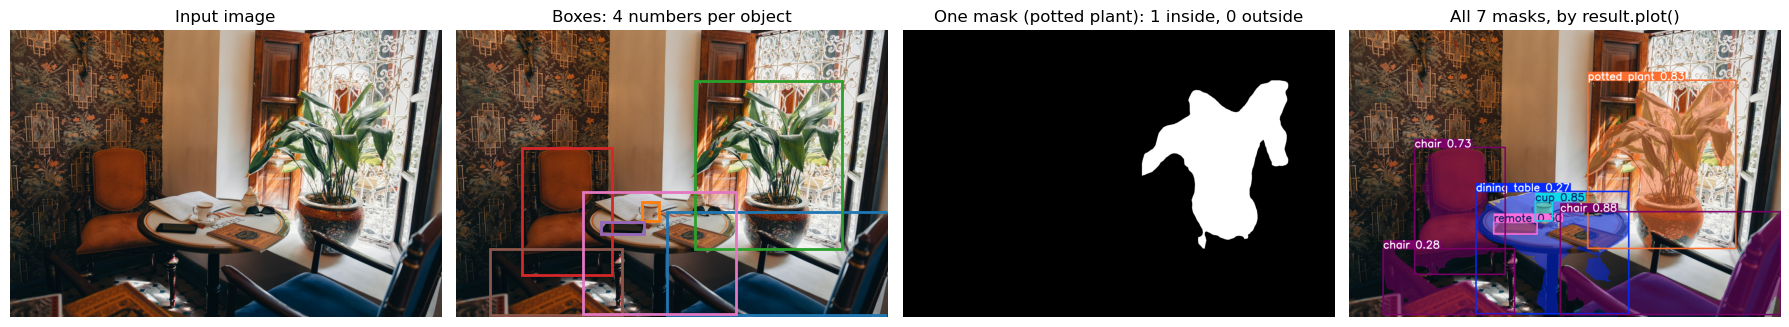

In [11]:
mask_index = 2
mask_class = retina_result.names[int(retina_result.boxes.cls[mask_index])]
one_mask = retina_result.masks.data[mask_index].cpu().numpy()

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

axes[0].imshow(image)
axes[0].set_title('Input image')
axes[0].axis('off')

axes[1].imshow(image)
for index in range(len(retina_result.boxes)):
    x1, y1, x2, y2 = retina_result.boxes.xyxy[index].cpu().numpy()
    axes[1].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                                edgecolor=plt.cm.tab10(index % 10), linewidth=2))
axes[1].set_title('Boxes: 4 numbers per object')
axes[1].axis('off')

axes[2].imshow(one_mask, cmap='gray')
axes[2].set_title(f'One mask ({mask_class}): 1 inside, 0 outside')
axes[2].axis('off')

axes[3].imshow(retina_result.plot()[:, :, ::-1])
axes[3].set_title(f'All {len(retina_result.boxes)} masks, by result.plot()')
axes[3].axis('off')

plt.tight_layout(); plt.show()

- Box → where an object is; mask → which pixels are the object
- `plot()` colours by class → the chairs share one colour, yet each has its own mask

---
## Step 7. What the Mask Buys You

- A mask gives the object's pixel count, a box only its extent
- Mask area / box area → how much of its box the object fills

In [12]:
print('object          mask pixels   box pixels   fill')
for index in range(len(retina_result.boxes)):
    class_index = int(retina_result.boxes.cls[index])
    x1, y1, x2, y2 = retina_result.boxes.xyxy[index].cpu().numpy()
    box_pixels = (x2 - x1) * (y2 - y1)
    mask_pixels = float(retina_result.masks.data[index].cpu().numpy().sum())
    print(f'{retina_result.names[class_index]:<14s} {mask_pixels:11.0f} {box_pixels:12.0f}   '
          f'{mask_pixels / box_pixels:.3f}')

object          mask pixels   box pixels   fill
chair               199206       520783   0.383
cup                   6474         7702   0.841
potted plant        279221       570899   0.489
chair               161199       264206   0.610
remote               10673        12182   0.876
chair                99370       199288   0.499
dining table        164533       428933   0.384


- Compact objects fill their box (`cup` 0.84, `remote` 0.88); wide or hollow ones do not (chairs, plant, table 0.38–0.61)
- Low fill → the box is mostly background

---
## Step 8. The Same Two Calls on Another Image

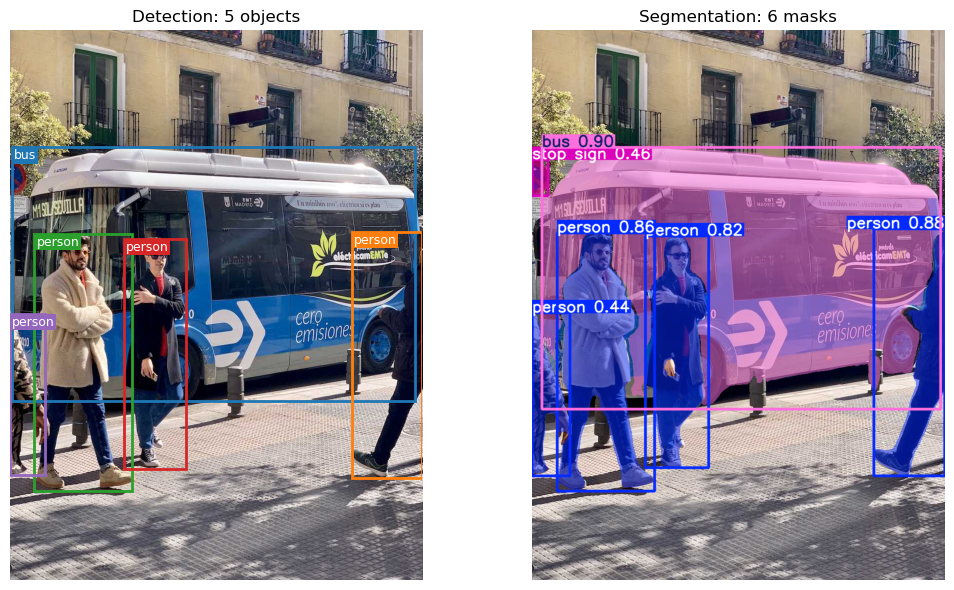

In [13]:
second_image = np.array(Image.open(second_image_path).convert('RGB'))
second_detection = detection_model.predict(source=str(second_image_path), conf=0.25, verbose=False)[0]
second_segmentation = segmentation_model.predict(source=str(second_image_path), conf=0.25,
                                                 retina_masks=True, verbose=False)[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 6))

axes[0].imshow(second_image)
for index in range(len(second_detection.boxes)):
    class_index = int(second_detection.boxes.cls[index])
    x1, y1, x2, y2 = second_detection.boxes.xyxy[index].cpu().numpy()
    instance_color = plt.cm.tab10(index % 10)
    axes[0].add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                                fill=False, edgecolor=instance_color, linewidth=2))
    axes[0].text(x1 + 4, y1 + 4, second_detection.names[class_index],
                 color='white', fontsize=9, va='top', ha='left', clip_on=True,
                 bbox=dict(facecolor=instance_color, edgecolor='none', pad=1))
axes[0].set_title(f'Detection: {len(second_detection.boxes)} objects')
axes[0].axis('off')

axes[1].imshow(second_segmentation.plot()[:, :, ::-1])
axes[1].set_title(f'Segmentation: {len(second_segmentation.boxes)} masks')
axes[1].axis('off')

plt.tight_layout(); plt.show()

- 5 boxes, 6 masks → the extra mask is the round sign at the left edge, labelled `stop sign` at 0.46, the nearest COCO class

---
## Summary

| Result | Holds | Note |
|:---|:---|:---|
| Detection | `boxes.xyxy`, `boxes.conf`, `boxes.cls`, one row per object | `boxes.xywhn` = the same rectangle divided by the image size |
| Segmentation | the same, plus `masks.data` | model-input resolution unless `retina_masks=True` |

- Mask pixels can be counted → their share of the box says how much of it the object fills

---
## Exercises

1. `conf=0.7`, rerun the detection listing — which objects disappear, and what were their confidences?
2. Print `boxes.xywhn` for every object — does any value fall outside 0 to 1?
3. Draw only the object with the largest mask area, using the mask pixel counts from Step 7.

In [14]:
# Write your code here